# Stage 0 — Raw data intake (NASA POWER, Sylhet, 1981–2025)

**Goal of this notebook:** read the raw NASA POWER file *without modifying it*, check its quality carefully, and save a
minimally parsed copy (only `-999 → NaN`, plus a proper date index) to `data/processed/power_parsed.parquet`.

**What we do *not* do here:** no imputation, no feature engineering, no dropping of variables, no train/test split.
Every problem we find is **shown and documented**, and fixes are left to the next stage (CLAUDE.md rule 12).

Why this stage matters for the paper: reviewers will want to know that the data are complete, physically plausible and
homogeneous over time. Problems in this stage (e.g. a variable that changes its data source halfway) silently damage every
model later, so we look before we learn.

### Step 1 — Setup: imports, paths, seed, library versions

**WHAT:** import libraries, define project paths, fix the random seed, print package versions.

**WHY:** recording versions makes the analysis reproducible (a reviewer can re-create the environment). Paths are
defined relative to the project root so the notebook works on any machine. Nothing random happens in this notebook,
but we set the seed anyway as a habit (rule 15).

**Alternatives considered:** a `config.py` in `src/` — sensible later, once several notebooks share settings; for now,
explicit paths in the notebook are easier to read.

**Look for:** no import errors; note the pandas version (date parsing behaviour differs between pandas 1.x and 2.x+).

In [1]:
import hashlib, sys
from pathlib import Path
import numpy as np, pandas as pd, matplotlib
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW = ROOT / "data/raw/sylhet_power_daily_AG_1981-2025_raw.csv"
PROC, FIG, TAB = ROOT / "data/processed", ROOT / "reports/figures", ROOT / "reports/tables"
for p in (PROC, FIG, TAB):
    p.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 140, "display.max_columns", 30)
print("python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__)

python 3.13.16 | pandas 3.0.5 | numpy 2.5.3 | matplotlib 3.11.2


**Interpretation:** the environment loads. We work with pandas 3.x, which uses copy-on-write by default — good for us,
because it reduces the risk of accidentally modifying a DataFrame we think is a copy.

**Decision:** record these versions in `DECISIONS.md`; later we will pin them in a `requirements.txt`.

**Paper note:** *All analyses were performed in Python 3.13 using pandas, NumPy and Matplotlib; exact package versions are
provided in the accompanying repository to ensure reproducibility.*

### Step 2 — Fingerprint the raw file and print the metadata header in full

**WHAT:** compute a SHA-256 checksum of the raw file, then print every line between `-BEGIN HEADER-` and `-END HEADER-`.

**WHY:** (1) the checksum is a fingerprint: if we compute it again at the end of the notebook and it is unchanged, we
have *proved* the raw file was not modified (rule: raw data is read-only). (2) The header is the official metadata from
NASA POWER: units, the missing-value code (`-999`), the grid-cell elevation and the source product of each variable.
We must read it before we trust any column.

**Alternatives considered:** hard-coding `skiprows=21` — fragile; if POWER changes the header length the load breaks
silently. We instead *find* the header end programmatically.

**Look for:** the missing-value code, the units of each parameter, and which source product (MERRA-2, CERES, IMERG)
each variable comes from.

In [2]:
def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

RAW_SHA = sha256(RAW)
print("SHA-256 of raw file:", RAW_SHA, "\n")

lines = RAW.read_text().splitlines()
end = next(i for i, l in enumerate(lines) if l.strip() == "-END HEADER-")
header_lines = lines[: end + 1]
print("\n".join(header_lines))
print(f"\n[{len(header_lines)} header lines; data table starts at line {end + 2}]")

SHA-256 of raw file: 396f799b5cf6a551aae8de603e9f23cdbb7cc9fdbdbf38face8885169cdba7d8 

-BEGIN HEADER-
NASA/POWER Source Native Resolution Daily Data 
Dates (month/day/year): 01/01/1981 through 12/31/2025 in UTC
Location: latitude  24.9157   longitude 91.832 
elevation from MERRA-2: Average for 0.5 x 0.625 degree lat/lon region = 103.47 meters
The value for missing source data that cannot be computed or is outside of the sources availability range: -999 
parameter(s): 
QV2M                  MERRA-2 Specific Humidity at 2 Meters (g/kg) 
RH2M                  MERRA-2 Relative Humidity at 2 Meters (%) 
IMERG_PRECTOT         MERRA-2 Total Precipitation (mm/day) 
T2M                   MERRA-2 Temperature at 2 Meters (C) 
T2M_MAX               MERRA-2 Temperature at 2 Meters Maximum (C) 
T2M_MIN               MERRA-2 Temperature at 2 Meters Minimum (C) 
T2MDEW                MERRA-2 Dew/Frost Point at 2 Meters (C) 
PS                    MERRA-2 Surface Pressure (kPa) 
WS2M                  M

**Interpretation:**
- **Missing-value code is `-999`.** Any `-999` is "no data", not a real measurement.
- Data are a **single grid cell** (MERRA-2 cell of 0.5° × 0.625°, mean elevation 103.47 m) around lat 24.9157, lon 91.832.
  This is a *gridded reanalysis/satellite* product, not a rain-gauge station — important when we compare to station studies.
- Three source families are mixed: **MERRA-2** (reanalysis; temperature, humidity, pressure, wind, PRECTOTCORR),
  **CERES SYN1deg** (satellite radiation), and **IMERG** (satellite precipitation).
- ⚠️ **Header inconsistency:** `IMERG_PRECTOT` is described as *"MERRA-2 Total Precipitation"*. The variable name says
  IMERG (NASA GPM satellite precipitation), and the data behave like a different product from `PRECTOTCORR`
  (we will see this in Step 9). We treat this as a **metadata labelling error in the POWER header** and must verify it
  against the POWER parameter documentation before citing it.
- Dates are in **UTC**. Sylhet is UTC+6, so a POWER "day" runs from 06:00 to 06:00 local time. This matters for rule 5
  (what is "known at the end of day t").

**Decision:** read the table by skipping exactly the detected header lines; document the full header in `DATA_SOURCE.md`;
flag the IMERG label for verification.

**Paper note:** *Daily data were obtained from the NASA POWER Agroclimatology archive for the grid cell centred near
Sylhet (24.92°N, 91.83°E), combining MERRA-2 reanalysis, CERES SYN1deg radiation and GPM IMERG precipitation, with
calendar days defined in UTC.*

### Step 3 — Load the data table

**WHAT:** read the CSV into pandas, skipping the header lines we found, and look at shape, dtypes, first and last rows.

**WHY:** confirm that every column parsed as a number (a stray text value would turn a column into `object` dtype) and
that the file begins and ends where we expect.

**Alternatives considered:** `na_values=-999` at load time would replace sentinels immediately. We **don't** do that
yet, because we first want to *count* the `-999` values explicitly (rule 12: show the problem before fixing it).

**Look for:** 15 columns, all numeric; first row 1981 DOY 1; last row 2025 DOY 365.

In [3]:
raw = pd.read_csv(RAW, skiprows=len(header_lines))
print("shape:", raw.shape)
print(raw.dtypes.to_string())
display(raw.head(3)); display(raw.tail(3))

shape: (16436, 15)
YEAR                   int64
DOY                    int64
QV2M                 float64
RH2M                 float64
IMERG_PRECTOT        float64
T2M                  float64
T2M_MAX              float64
T2M_MIN              float64
T2MDEW               float64
PS                   float64
WS2M                 float64
WD2M                 float64
WS10M                float64
ALLSKY_SFC_SW_DWN    float64
PRECTOTCORR          float64


,YEAR,DOY,QV2M,RH2M,IMERG_PRECTOT,T2M,T2M_MAX,T2M_MIN,T2MDEW,PS,WS2M,WD2M,WS10M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
0,1981,1,9.10,72.44,-999.0,17.72,23.01,12.67,12.53,100.13,1.22,70.6,2.10,-999.0,0.00
1,1981,2,9.05,72.92,-999.0,17.56,23.21,11.70,12.44,100.16,1.20,75.6,2.03,-999.0,0.01
2,1981,3,8.74,70.55,-999.0,17.57,22.89,11.66,11.93,100.13,1.15,23.8,1.83,-999.0,0.00


,YEAR,DOY,QV2M,RH2M,IMERG_PRECTOT,T2M,T2M_MAX,T2M_MIN,T2MDEW,PS,WS2M,WD2M,WS10M,ALLSKY_SFC_SW_DWN,PRECTOTCORR
16433,2025,363,8.64,82.27,0.0,15.04,21.10,9.62,11.79,100.29,1.18,-8530.0,2.07,4.78,0.00
16434,2025,364,8.66,85.82,0.0,14.21,19.62,9.26,11.82,100.20,1.12,-7109.0,1.80,8.46,0.02
16435,2025,365,8.90,82.47,0.0,15.33,21.55,9.97,12.19,100.05,1.18,-8223.0,2.06,6.45,0.00


**Interpretation:** 16,436 rows × 15 columns, all numeric (`int64` for YEAR/DOY, `float64` otherwise). The file runs from
1981-DOY 1 to 2025-DOY 365. Already in the first rows we see `-999.0` in `IMERG_PRECTOT` and `ALLSKY_SFC_SW_DWN`
(missing early in the record), and in the **last rows `WD2M` shows values like −8530**, which is impossible for a wind
direction (0–360°). We will investigate this in Step 7.

**Decision:** the table parsed cleanly; continue with date checks.

**Paper note:** *The raw archive comprised 16,436 daily records of 13 meteorological variables.*

### Step 4 — Build a datetime index from YEAR and DOY

**WHAT:** convert `YEAR` + `DOY` (day of year, 1–366) into a real date, using the format `%Y%j`, and use it as the index.

**WHY:** every later step (lags, chronological splits, seasonal features) needs a true calendar date. Building it from
YEAR/DOY with `errors="raise"` also *validates* the DOY values: DOY 366 in a non-leap year would raise an error instead of
silently rolling into the next year.

**Alternatives considered:** `pd.Timestamp(year) + pd.to_timedelta(doy-1, "D")` — works, but would silently accept
DOY 366 in a non-leap year (it would become 1 January of the next year and create a duplicate). The `%j` parser is stricter.

**Look for:** no parsing error; dates ranging 1981-01-01 to 2025-12-31.

In [4]:
date = pd.to_datetime(raw["YEAR"].astype(str) + raw["DOY"].astype(str).str.zfill(3),
                      format="%Y%j", errors="raise")
df = raw.set_index(date).rename_axis("date")
print("first:", df.index.min().date(), "| last:", df.index.max().date())
print("DOY range:", raw["DOY"].min(), "-", raw["DOY"].max())
print("years with 366 days:", sorted(df.groupby("YEAR").size().loc[lambda s: s == 366].index.tolist()))

first: 1981-01-01 | last: 2025-12-31
DOY range: 1 - 366
years with 366 days: [1984, 1988, 1992, 1996, 2000, 2004, 2008, 2012, 2016, 2020, 2024]


**Interpretation:** all YEAR/DOY pairs are valid dates. Exactly the 11 leap years (1984, 1988, …, 2024) have 366 days,
so DOY 366 appears only where it should.

**Decision:** use `date` (daily, UTC) as the index for all later notebooks.

**Paper note:** *Calendar dates were reconstructed from year and day-of-year fields, and all leap days were verified to
fall in leap years.*

### Step 5 — Row count, duplicate dates, and missing dates

**WHAT:** compare the number of rows to the number of days between 1981-01-01 and 2025-12-31; count duplicated dates;
list dates that are absent.

**WHY:** a forecasting model for day *t+1* assumes that "the next row is the next day". A missing day would make a lag
feature point to the wrong date; a duplicated day would leak information and double-count. This check guarantees the
time axis is regular.

**Alternatives considered:** only comparing `len(df)` to the expected number — insufficient, because one missing day plus
one duplicated day would give the right count but a broken calendar. We therefore check both.

**Look for:** row count = expected days; 0 duplicates; 0 missing dates.

In [5]:
full = pd.date_range("1981-01-01", "2025-12-31", freq="D")
missing_dates = full.difference(df.index)
print("expected days :", len(full))
print("rows in file  :", len(df))
print("duplicate dates:", df.index.duplicated().sum())
print("missing dates  :", len(missing_dates), list(missing_dates[:10]))
print("index strictly increasing:", df.index.is_monotonic_increasing and df.index.is_unique)

expected days : 16436
rows in file  : 16436
duplicate dates: 0
missing dates  : 0 []
index strictly increasing: True


**Interpretation:** 16,436 rows = 16,436 expected days, no duplicates, no gaps, and the index is strictly increasing.
The calendar is complete and regular, so a 1-row shift equals a 1-day shift.

**Decision:** no re-indexing or gap-filling of dates is needed. We can safely build lag features with `.shift()` later.

**Paper note:** *The daily series was temporally complete, with no missing or duplicated dates over the 45-year record
(16,436 days).*

### Step 6 — Count the `-999` missing-value code per column

**WHAT:** count how many cells equal exactly `-999` in each column, and as a percentage of all days.

**WHY:** the header told us `-999` means "missing". If we fed `-999` into a model it would be treated as an extremely
cold / dry / dark day — a severe silent error. We count before replacing so the problem is visible (rule 12).

**Alternatives considered:** also searching for other sentinels (e.g. `-99`, `-9999`). We check "any value ≤ −99" as a
safety net; anything found there that is *not* exactly −999 will be investigated separately.

**Look for:** which columns contain `-999` and how many; any other suspicious large negative numbers.

In [6]:
vars_ = [c for c in df.columns if c not in ("YEAR", "DOY")]
miss = pd.DataFrame({
    "n_minus999": (df[vars_] == -999).sum(),
    "pct_minus999": ((df[vars_] == -999).mean() * 100).round(2),
    "n_other_le_-99": ((df[vars_] <= -99) & (df[vars_] != -999)).sum(),
})
miss.to_csv(TAB / "00_missing_codes_per_column.csv")
miss

,n_minus999,pct_minus999,n_other_le_-99
QV2M,0,0.00,0
RH2M,0,0.00,0
IMERG_PRECTOT,6209,37.78,0
T2M,0,0.00,0
T2M_MAX,0,0.00,0
T2M_MIN,0,0.00,0
T2MDEW,0,0.00,0
PS,0,0.00,0
WS2M,0,0.00,0
WD2M,0,0.00,4749


**Interpretation:**
- `IMERG_PRECTOT`: **6,209** days (37.8 %) are `-999`.
- `ALLSKY_SFC_SW_DWN` (solar radiation): **1,095** days (6.7 %) are `-999` — exactly 3 years.
- All other variables have no `-999`.
- ⚠️ **`WD2M` has 4,749 values ≤ −99 that are *not* −999.** This is a different kind of problem: not a declared missing code,
  but invalid values. Replacing only `-999` will *not* catch it. We investigate in Step 7.

**Decision:** replace exactly `-999` by `NaN` (the only transformation allowed in this stage). Flag `WD2M` as a separate issue.

**Paper note:** *Missing values, encoded as −999 in the source files, affected only satellite precipitation (IMERG; 37.8 %
of days) and surface shortwave radiation (6.7 %).*

### Step 7 — Replace `-999` with NaN, then check physical ranges and units

**WHAT:** create `df_nan` where `-999 → NaN`, then compare each variable's min/max with a physically plausible range for
Sylhet, using the units from the header.

**WHY:** a value outside a plausible range is either a unit mistake (e.g. pressure in hPa vs kPa), a sentinel we did not
know about, or a processing error. Catching it now prevents a model from learning nonsense.

**Alternatives considered:** automatic outlier detection (z-scores, IQR). For rainfall that would wrongly flag genuine
extreme events (Sylhet routinely has >150 mm days). Physical bounds are more defensible for intake checks; statistical
outliers are left for EDA.

**Look for:** any `ok = False` row. Check units too: PS should be ~100 **kPa** (not 1000 hPa); QV2M in **g/kg** (~5–25).

In [7]:
df_nan = df.replace(-999, np.nan)
units = {l.split()[0]: l[l.rfind("(") + 1 : l.rfind(")")] for l in header_lines if "(" in l and l.split()[0] in vars_}
bounds = {"QV2M": (0, 30), "RH2M": (0, 100), "IMERG_PRECTOT": (0, 500), "T2M": (-5, 45), "T2M_MAX": (-5, 50),
          "T2M_MIN": (-10, 40), "T2MDEW": (-15, 35), "PS": (95, 105), "WS2M": (0, 30), "WD2M": (0, 360),
          "WS10M": (0, 40), "ALLSKY_SFC_SW_DWN": (0, 35), "PRECTOTCORR": (0, 500)}
rng = pd.DataFrame({"unit": pd.Series(units), "min": df_nan[vars_].min(), "max": df_nan[vars_].max(),
                    "mean": df_nan[vars_].mean().round(2),
                    "lo": {k: v[0] for k, v in bounds.items()}, "hi": {k: v[1] for k, v in bounds.items()}})
rng["n_out_of_range"] = [((df_nan[c] < rng.loc[c, "lo"]) | (df_nan[c] > rng.loc[c, "hi"])).sum() for c in rng.index]
rng["ok"] = rng["n_out_of_range"] == 0
rng.to_csv(TAB / "00_range_checks.csv")
rng

,unit,min,max,mean,lo,hi,n_out_of_range,ok
QV2M,g/kg,3.07,24.18,15.08,0,30,0,True
RH2M,%,17.84,96.87,74.84,0,100,0,True
IMERG_PRECTOT,mm/day,0.00,229.39,10.15,0,500,0,True
T2M,C,10.90,33.64,24.59,-5,45,0,True
T2M_MAX,C,17.13,41.50,29.31,-5,50,0,True
T2M_MIN,C,4.22,28.76,20.27,-10,40,0,True
T2MDEW,C,-3.03,27.99,19.27,-15,35,0,True
PS,kPa,97.88,100.92,99.63,95,105,0,True
WS2M,m/s,0.57,6.75,1.51,0,30,0,True
WD2M,Degrees,-8998.00,360.00,-1970.80,0,360,4749,False


**Interpretation:** every variable lies inside its plausible range **except `WD2M`** (4,749 out-of-range values,
minimum ≈ −9,000°). Units are confirmed: pressure ≈ 99.6 kPa (consistent with ~100 m elevation), specific humidity 2–24 g/kg,
temperatures 4–42 °C, radiation up to ~29 MJ m⁻² day⁻¹ (theoretical clear-sky maximum at 25°N is ≈ 30–32), daily
precipitation maxima of 229 mm (IMERG) and 288 mm (PRECTOTCORR) — large but realistic for Sylhet, one of the wettest
regions of Bangladesh.

**Decision:** keep all non-WD2M values as they are. Investigate `WD2M` next before deciding anything.

**Paper note:** *All variables except 2-m wind direction fell within physically plausible bounds, and reported units
(kPa, g kg⁻¹, °C, m s⁻¹, MJ m⁻² day⁻¹, mm day⁻¹) were consistent with the observed magnitudes.*

### Step 8 — Investigate the invalid wind direction (`WD2M`)

**WHAT:** find when the invalid `WD2M` values start, whether *every* day after that is invalid, and plot the series.

**WHY:** rule 12 — show the problem before fixing it. We need to know whether this is a few glitches (could be set to NaN)
or a systematic break (the variable may be unusable after a date).

**Alternatives considered:** "decoding" the values (e.g. taking them modulo 360). We will look at it, but we will **not**
use it: without documentation from NASA POWER, any decoding would be a guess, and a guessed variable cannot be defended
in a paper.

**Look for:** the first and last invalid date, and whether valid values ever re-appear.

invalid WD2M days: 4749


first invalid: 2012-12-31 | last valid: 2012-12-30
all days from first invalid onward are invalid: True
count    4749.0
mean    -7236.0
std       906.0
min     -8998.0
25%     -8133.0
50%     -7040.0
75%     -6661.0
max     -5401.0


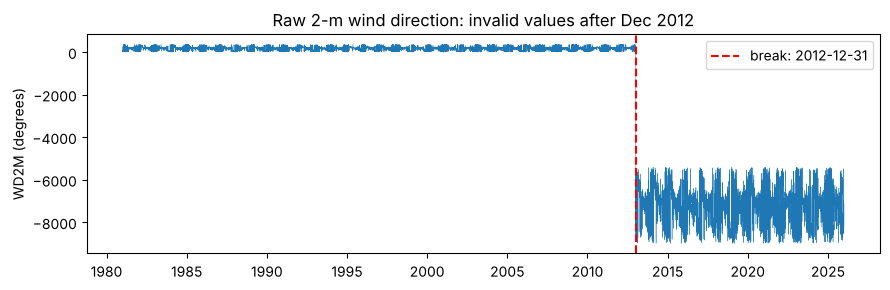

In [8]:
bad = (df_nan["WD2M"] < 0) | (df_nan["WD2M"] > 360)
print("invalid WD2M days:", bad.sum())
print("first invalid:", bad.idxmax().date(), "| last valid:", df_nan.index[~bad].max().date())
print("all days from first invalid onward are invalid:", bad.loc[bad.idxmax():].all())
print(df_nan.loc[bad, "WD2M"].describe().round(0).to_string())

fig, ax = plt.subplots(figsize=(9, 3))
ax.plot(df_nan.index, df_nan["WD2M"], lw=0.3)
ax.axvline(bad.idxmax(), color="red", ls="--", label=f"break: {bad.idxmax().date()}")
ax.set(ylabel="WD2M (degrees)", title="Raw 2-m wind direction: invalid values after Dec 2012"); ax.legend()
fig.tight_layout(); fig.savefig(FIG / "00_wd2m_break.png", dpi=300); plt.show()

**Interpretation:** from **2012-12-31 onward, every single `WD2M` value is invalid** (range ≈ −9,000 to −5,400, integer-like),
while 1981-01-01 → 2012-12-30 is entirely within 0–360°. This is a systematic break in the delivered product (likely a
processing/encoding fault on the POWER side), not random noise. It affects 29 % of the record — and **exactly the most
recent years, which will be our validation and test periods.**

**Decision (proposed, needs your approval):** we do *not* fix it here. Options for Stage 1:
1. **Drop `WD2M`** and rely on `WS2M`/`WS10M` (simplest, defensible).
2. Re-download wind as **U/V components** (e.g. `U2M`, `V2M` or `U10M`, `V10M` from POWER) and compute direction ourselves —
   the physically better option (direction is circular, so u/v or sin/cos encoding is needed anyway).
3. Set post-2012 to NaN and impute — **not recommended**: the test period would be 100 % imputed.
`power_parsed.parquet` keeps the raw `WD2M` values unchanged, and the problem is documented.

**Paper note:** *The 2-m wind direction (WD2M) series contained physically impossible values for every day from
31 December 2012 onward and was therefore excluded from the predictor set [or: replaced by direction derived from
re-downloaded wind components].*

### Step 9 — Internal consistency between related variables

**WHAT:** check relationships that must hold physically: `T2M_MIN ≤ T2M ≤ T2M_MAX`, dew point ≤ air temperature,
`WS10M ≥ WS2M` (wind usually increases with height), precipitation ≥ 0.

**WHY:** each column can be inside its range and still be wrong *relative to another column* (e.g. min and max swapped).
Such checks catch column mix-ups and processing errors that range checks miss.

**Alternatives considered:** recomputing RH from T2M and T2MDEW (Magnus formula) and comparing to RH2M — a stronger test,
but daily means of non-linear quantities don't match exactly, so it would need a tolerance; we keep it for EDA.

**Look for:** zero (or near-zero) violations. A small tolerance (0.05) is allowed for rounding to two decimals.

In [9]:
d, tol = df_nan, 0.05
checks = {
    "T2M_MIN > T2M_MAX": (d.T2M_MIN > d.T2M_MAX + tol).sum(),
    "T2M outside [MIN, MAX]": ((d.T2M < d.T2M_MIN - tol) | (d.T2M > d.T2M_MAX + tol)).sum(),
    "T2MDEW > T2M": (d.T2MDEW > d.T2M + tol).sum(),
    "WS2M > WS10M": (d.WS2M > d.WS10M + tol).sum(),
    "negative PRECTOTCORR": (d.PRECTOTCORR < 0).sum(),
    "negative IMERG_PRECTOT": (d.IMERG_PRECTOT < 0).sum(),
}
pd.Series(checks, name="n_violations").to_frame()

,n_violations
T2M_MIN > T2M_MAX,0
"T2M outside [MIN, MAX]",0
T2MDEW > T2M,0
WS2M > WS10M,0
negative PRECTOTCORR,0
negative IMERG_PRECTOT,0


**Interpretation:** zero violations in every check. The temperature, humidity and wind columns are mutually consistent,
so there is no sign of swapped or mislabelled columns among them.

**Decision:** no action needed for these variables.

**Paper note:** *Internal consistency checks (daily minimum ≤ mean ≤ maximum temperature, dew point ≤ air temperature,
2-m ≤ 10-m wind speed, non-negative precipitation) revealed no violations.*

### Step 10 — Where do missing values occur over time?

**WHAT:** compute the fraction of missing days per year and variable, find the first and last valid date of the two
incomplete variables, check for gaps *inside* their valid period, and draw a heat-map.

**WHY:** the *pattern* of missingness decides what we can do. Missing at the **start** of the record (a product did not
exist yet) is very different from random gaps: it cannot be imputed sensibly, it limits the usable training period, and
if a model uses the variable, the training period must start when the variable starts.

**Alternatives considered:** `missingno` library plots — nice, but an extra dependency for one figure; a pandas pivot +
`imshow` is enough.

**Look for:** whether missingness is a block at the beginning or scattered; any gaps after the first valid date.

IMERG_PRECTOT      first valid 1998-01-01  last valid 2025-12-31  NaN before first:  6209  NaN inside valid period: 0
ALLSKY_SFC_SW_DWN  first valid 1984-01-01  last valid 2025-12-31  NaN before first:  1095  NaN inside valid period: 0


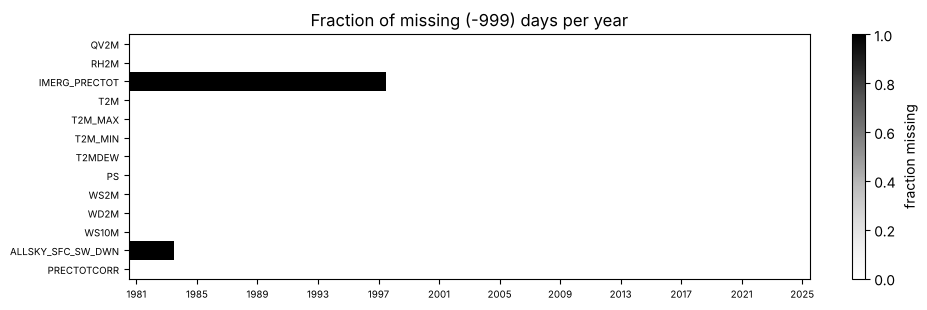

In [10]:
for c in ["IMERG_PRECTOT", "ALLSKY_SFC_SW_DWN"]:
    s = df_nan[c]; first, last = s.first_valid_index(), s.last_valid_index()
    print(f"{c:18s} first valid {first.date()}  last valid {last.date()}  "
          f"NaN before first: {s[:first].isna().sum():5d}  NaN inside valid period: {s[first:last].isna().sum()}")

miss_year = df_nan[vars_].isna().groupby(df_nan.index.year).mean()
miss_year.round(3).to_csv(TAB / "00_missing_fraction_by_year.csv")

fig, ax = plt.subplots(figsize=(10, 3.2))
im = ax.imshow(miss_year.T, aspect="auto", cmap="Greys", vmin=0, vmax=1)
ax.set_yticks(range(len(vars_)), vars_, fontsize=7)
ax.set_xticks(range(0, len(miss_year), 4), miss_year.index[::4], fontsize=7)
ax.set_title("Fraction of missing (-999) days per year"); fig.colorbar(im, ax=ax, label="fraction missing")
fig.tight_layout(); fig.savefig(FIG / "00_missing_by_year.png", dpi=300); plt.show()

**Interpretation:** missingness is **structural, not random**:
- `ALLSKY_SFC_SW_DWN` is missing for all of **1981–1983** and complete from **1984-01-01** onward (no internal gaps).
  POWER radiation before CERES SYN1deg (which starts in 2000) comes from an older product (GEWEX SRB), so even the
  "complete" part may contain a source change around 2000 — to check in EDA.
- `IMERG_PRECTOT` is missing for all of **1981–1997** and complete from **1998-01-01** (no internal gaps). This matches
  the start of the IMERG satellite record (TRMM era).
- No variable has gaps *inside* its available period.

**Decision:** no imputation here. This creates a design choice for Stage 1: if we use IMERG (as target or input), the
usable period is **1998–2025 (28 years)**; if we use radiation only, it is 1984–2025.

**Paper note:** *Missing data were confined to the beginning of the record and reflect product availability rather than
random gaps: shortwave radiation is available from 1984 and IMERG precipitation from 1998, with no missing days thereafter.*

### Step 11 — Precipitation sanity check: annual totals and rain-day frequency

**WHAT:** compare the two precipitation products (`PRECTOTCORR`, `IMERG_PRECTOT`) through annual totals over time and the
fraction of rain days at our three thresholds (0.1, 1, 2.5 mm).

**WHY:** precipitation will be our **target**. Before choosing which product is the target, we must check that it is
(a) realistic for Sylhet (observed long-term mean ≈ 4,000+ mm/yr at the BMD station) and (b) **homogeneous in time**. A
step change in the target series would make a chronological test set look different from the training set for reasons
that have nothing to do with weather.

**Alternatives considered:** formal homogeneity tests (Pettitt, SNHT). Useful for the paper; a plot of annual totals is
the first, most transparent step, and we can add a formal test in EDA if needed.

**Look for:** level shifts in annual totals; how different the two products are in level and rain-day frequency.

Mean annual total (mm):
               1981-1997  1998-2015  2016-2025
PRECTOTCORR       1925.0     2970.0     5377.0
IMERG_PRECTOT        NaN     3680.0     3757.0

Fraction of rain days, 1998-2025:
                >= 0.1 mm  >= 1.0 mm  >= 2.5 mm
PRECTOTCORR        0.608      0.528      0.473
IMERG_PRECTOT      0.541      0.475      0.418

Daily correlation 1998-2025 (Pearson): 0.618


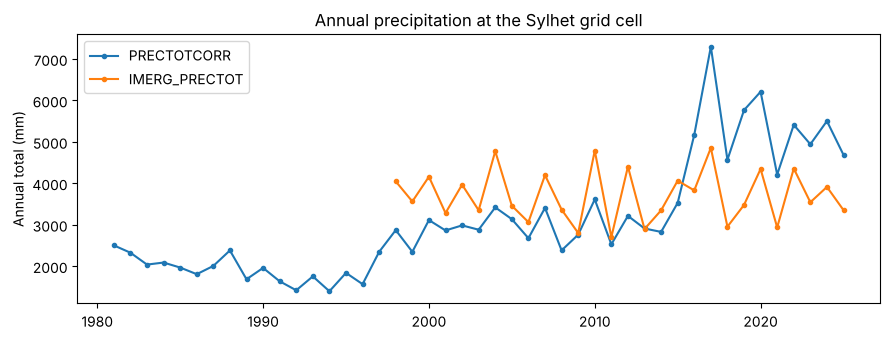

In [11]:
annual = df_nan.groupby(df_nan.index.year)[["PRECTOTCORR", "IMERG_PRECTOT"]].sum(min_count=360)
annual.round(0).to_csv(TAB / "00_annual_precip_totals.csv")
periods = {"1981-1997": slice("1981", "1997"), "1998-2015": slice("1998", "2015"), "2016-2025": slice("2016", "2025")}
print("Mean annual total (mm):")
print(pd.DataFrame({k: annual.loc[int(v.start):int(v.stop)].mean() for k, v in periods.items()}).round(0))

common = df_nan.loc["1998":, ["PRECTOTCORR", "IMERG_PRECTOT"]]
freq = pd.DataFrame({f">= {t} mm": (common >= t).mean().round(3) for t in (0.1, 1.0, 2.5)})
print("\nFraction of rain days, 1998-2025:\n", freq)
print("\nDaily correlation 1998-2025 (Pearson):", common.corr().iloc[0, 1].round(3))

fig, ax = plt.subplots(figsize=(9, 3.5))
annual.plot(ax=ax, marker="o", ms=3)
ax.set(ylabel="Annual total (mm)", xlabel="", title="Annual precipitation at the Sylhet grid cell")
fig.tight_layout(); fig.savefig(FIG / "00_annual_precip_totals.png", dpi=300); plt.show()

**Interpretation (important):**
- **`PRECTOTCORR` is not homogeneous.** Its mean annual total is ≈ 1,925 mm in 1981–1997, ≈ 2,970 mm in 1998–2015 and
  ≈ 5,380 mm in 2016–2025 — the level nearly **triples** over the record, with a sharp jump around 2016. Real climate in
  Sylhet did not change like this; such step changes are typical of reanalysis precipitation when the observations used
  for its correction change. The early period also badly *underestimates* Sylhet's known ~4,000 mm/yr.
- **`IMERG_PRECTOT` is stable** (≈ 2,700–4,900 mm/yr, period means 3,680 vs 3,757 mm, no visible shift) and closer to station climatology,
  but only exists from 1998.
- The two products disagree day-to-day (correlation ≈ 0.62) and in rain-day frequency (≥ 1 mm: 52.8 % of days for PRECTOTCORR vs 47.5 % for IMERG), so **the choice of target product
  will change every result in the paper**.

**Decision (needs your approval before Stage 1):** this is the most important finding of Stage 0. Options:
1. **Target = `IMERG_PRECTOT`, period 1998–2025** (homogeneous satellite target; MERRA-2 variables as inputs). *My
   recommendation.*
2. Target = `PRECTOTCORR`, 1981–2025 — longer, but the test period (most recent years) would have a different rainfall
   regime than training; models would appear to "fail" because of the data product, not the weather.
3. Report both as a robustness analysis (more work, but strong for the paper).
Either way, `PRECTOTCORR` is a *model output*, so using it as an input or target requires the same "end of day t" care
as any other variable.

**Paper note:** *MERRA-2 bias-corrected precipitation (PRECTOTCORR) exhibited marked inhomogeneity at the study grid cell,
with mean annual totals rising from about 1,925 mm (1981–1997) to 5,380 mm (2016–2025), whereas GPM IMERG precipitation
showed no comparable shift; we therefore [selected IMERG as the reference target for 1998–2025].*

### Step 12 — Save the minimally parsed copy and prove the raw file is untouched

**WHAT:** save `df_nan` (date index, `-999 → NaN`, nothing else changed) to `data/processed/power_parsed.parquet`;
reload it to verify an exact round-trip; recompute the raw file checksum.

**WHY:** later notebooks must read from `data/processed` (rule 15: no hidden state). Parquet keeps the dtypes and the
`DatetimeIndex` exactly (CSV would turn dates into strings and could change float precision). The checksum comparison
proves the raw file was read-only.

**Alternatives considered:** CSV — human-readable, but loses types; Feather — fast, but Parquet is more standard and
compressed. We keep `YEAR` and `DOY` columns so the file can be traced back to the raw rows.

**Look for:** `round-trip identical: True` and `raw file unchanged: True`.

In [12]:
out = PROC / "power_parsed.parquet"
df_nan.to_parquet(out)
back = pd.read_parquet(out)
pd.testing.assert_frame_equal(back, df_nan, check_freq=False)
print("saved:", out.relative_to(ROOT), "| shape:", back.shape, "| round-trip identical: True")
print("NaN per column:", back.isna().sum()[lambda s: s > 0].to_dict())
print("raw file unchanged:", sha256(RAW) == RAW_SHA)

saved: data/processed/power_parsed.parquet | shape: (16436, 15) | round-trip identical: True
NaN per column: {'IMERG_PRECTOT': 6209, 'ALLSKY_SFC_SW_DWN': 1095}
raw file unchanged: True


**Interpretation:** the parsed file has 16,436 rows × 15 columns, a daily `DatetimeIndex`, NaN only where the raw file had
`-999` (IMERG 6,209; radiation 1,095), and reloads identically. The raw file's checksum is unchanged.
Note: `WD2M` invalid values are **still present** in this file on purpose — this file is "raw + parsing only".

**Decision:** `power_parsed.parquet` is the single entry point for Stage 1.

**Paper note:** *The raw archive was retained unaltered (SHA-256 recorded), and all subsequent processing was applied to
a parsed copy in which only the source missing-value code was converted to a null value.*

## Stage 0 summary

| Check | Result |
|---|---|
| Rows vs expected days (1981-01-01 → 2025-12-31) | 16,436 = 16,436 ✅ |
| Duplicate / missing dates | 0 / 0 ✅ |
| `-999` codes | IMERG_PRECTOT 6,209 (1981–1997); ALLSKY_SFC_SW_DWN 1,095 (1981–1983); others 0 |
| Physical ranges & units | all plausible **except WD2M** ⚠️ |
| WD2M | every value invalid from 2012-12-31 onward (−9,000…−5,400) ⚠️ |
| Internal consistency | no violations ✅ |
| PRECTOTCORR homogeneity | strong upward step changes (~1,925 → ~5,380 mm/yr) ⚠️ |
| IMERG_PRECTOT | complete & stable from 1998; header mislabels it as "MERRA-2" ⚠️ |

**Open decisions for you (before Stage 1):** target product (IMERG vs PRECTOTCORR), study period, and how to handle WD2M.

Outputs: `data/processed/power_parsed.parquet`, `reports/tables/00_*.csv`, `reports/figures/00_*.png`.